In [ ]:
%load_ext autoreload
%autoreload 2
%reload_ext autoreload

In [1]:
import pandas as pd
from tqdm.notebook import tqdm
import ast
tqdm.pandas()
from socialvec.socialvec import SocialVec
import random

from utils import parse_friends_ids

2025-12-29 11:54:13.164299: I tensorflow/core/util/port.cc:111] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-12-29 11:54:15.225253: I tensorflow/tsl/cuda/cudart_stub.cc:28] Could not find cuda drivers on your machine, GPU will not be used.
2025-12-29 11:54:18.826984: E tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:9342] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
2025-12-29 11:54:18.827126: E tensorflow/compiler/xla/stream_executor/cuda/cuda_fft.cc:609] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
2025-12-29 11:54:18.838833: E tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:1518] Unable to register cuBLAS factory: Attempting to regi

In [3]:
all_topics = pd.read_excel("../data/popular_accounts_manually_validated.xlsx", sheet_name=None)
#df_users = pd.read_excel("../data/new_mean_average_percision.xlsx", sheet_name="SelectedUsers")
df_users = pd.read_pickle("../data/users_selected_for_the_experiment2.pkl")

In [4]:
# if you used the excel for the df_users, you need to parse the users:
#convert data from string to list
#df_users["friends_ids"] = df_users.apply(parse_friends_ids, axis=1)

In [5]:
df_users = df_users[~df_users['account_selected_for'].isna()]

In [8]:
df_accounts = pd.DataFrame()

for i in all_topics:
    all_topics[i] = all_topics[i][all_topics[i]['use']==1].copy()
    df_accounts = pd.concat([df_accounts, all_topics[i]])

df_accounts = df_accounts[df_accounts['use']==1]
df_accounts['twitter_user_id'] = df_accounts['twitter_user_id'].astype(int)
df_accounts.drop(df_accounts.columns[df_accounts.columns.str.contains('unnamed',case = False)],axis = 1, inplace = True)

In [9]:
account_list = df_accounts['twitter_user_id'].values
topic_list = [t for t in all_topics]

In [10]:
#keep only users with the relevant topics (since we removed some)
print(df_users.shape[0])
df_users = df_users[df_users['topic'].isin(topic_list)]
print(df_users.shape[0])

13800
13800


In [11]:
def get_relevant_subset_users(x):
    return list(set(x).intersection(set(account_list)))

In [12]:
df_users["number_of_accounts_full_sv"] = df_users["friends_ids"].apply(lambda x: len(x))
df_users["experiment_accounts"] = df_users["friends_ids"].apply(get_relevant_subset_users)
df_users["number_of_accounts_from_experiment"] = df_users["experiment_accounts"].apply(lambda x: len(x))

In [13]:
minimal_number_of_accounts = 10

number_of_users_before_filtering = df_users.shape[0]
df_users = df_users[df_users["number_of_accounts_from_experiment"]>minimal_number_of_accounts]
print(f"removed {number_of_users_before_filtering - df_users.shape[0]} users in order to use only users who follow more than {minimal_number_of_accounts} users")
print(f"Using {df_users.shape[0]/number_of_users_before_filtering:.0%} of the users")

removed 2647 users in order to use only users who follow more than 10 users
Using 81% of the users


In [14]:
def find_number_of_categories_per_user(list_of_accounts):
    num_of_categories = 0
    for t in all_topics:
        all_topics[t]['twitter_user_id'] = all_topics[t]['twitter_user_id'].astype(int)
        if len (set(all_topics[t]['twitter_user_id'].values).intersection(set(list_of_accounts))) > 0:
            num_of_categories += 1
    return num_of_categories

In [15]:
df_users['number_of_categories_this_user_follows'] = df_users["experiment_accounts"].progress_apply(find_number_of_categories_per_user)

  0%|          | 0/11153 [00:00<?, ?it/s]

In [16]:
sv = SocialVec()

✅  Initializing Model
✅  Load Metadata


In [17]:
df_users["experiment_accounts_str"] = df_users["experiment_accounts"].progress_apply(lambda x: [str(i) for i in x])

  0%|          | 0/11153 [00:00<?, ?it/s]

### 16. Separation Logic
Define function to split friends into **Topic Accounts** (ground truth) and **Non-Topic Accounts** (context for embedding)

In [18]:
def seperate_topic_accounts(user_account_list, topic_account_list):
    user_accounts = set(user_account_list)
    topic_accounts = set(topic_account_list)
    return list(user_accounts - topic_accounts), list(user_accounts.intersection(topic_accounts))

### 17. Ranking Functions
Define `get_sv_rank` (Cosine Similarity) and `get_popular_rank` (Follower Count) to rank accounts.

In [19]:
from scipy.spatial.distance import cosine
import numpy as np
from typing import List, Tuple, Dict

def get_sv_rank(
    user_vec: np.ndarray,
    relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    """
    Build a DataFrame of cosine similarities between one user vector and
    all relevant account vectors.
    """
    records = []
    for i, row in relevant_vecs.iterrows():
        records.append({
            'account': row['twitter_screen_name'],
            'twitter_user_id':row['twitter_user_id'],
            'similarity': cosine(row['account_sv'], user_vec)
        })
    sv_ranked_list = pd.DataFrame(records).sort_values(by='similarity', ascending=True).reset_index(drop=True).reset_index()
    sv_ranked_list.rename(columns={'index':'rank'}, inplace=True)
    sv_ranked_list['rank'] = sv_ranked_list['rank'] + 1
    return sv_ranked_list

def get_popular_rank(
        relevant_vecs: pd.DataFrame
) -> pd.DataFrame:
    popularity_rank = relevant_vecs.sort_values(by=['followers_count'], ascending=False).reset_index(drop=True).reset_index()
    popularity_rank.rename(columns={'index':'rank',
                                    'twitter_screen_name':'account'}, inplace=True)
    popularity_rank['rank'] = popularity_rank['rank'] + 1
    return popularity_rank[['rank','account','twitter_user_id']]

### 18. Metric: Mean Average Precision (MAP)

### 19. Rank Normalization
Helper to filter a full ranked list down to specific topic accounts and reset rank indices (1, 2, 3...)

In [21]:
def reset_and_rank_topic_accounts(df, topic_accounts):
    df = df[df['twitter_user_id'].isin(topic_accounts)]
    df = df.reset_index(drop=True)
    df = df.reset_index()
    df['index'] = df['index'] + 1
    return df

### 20. Pre-calculate Embeddings
Compute SocialVec embeddings for all topic accounts once to optimize performance.

In [22]:
# Calculate Topics SV
for topic in topic_list:
    all_topics[topic]['account_sv'] = all_topics[topic]['twitter_user_id'].apply(lambda x: sv[x])

### 21. Topic Data Preparation
Define function to separate friends lists into context/target sets for a specific topic experiment.

In [24]:
def prepare_df_for_topic(topic, df_users):
    df_for_topic = df_users[df_users['topic'] == topic].copy()
    df_for_topic[["non_topic_accounts","topic_accounts"]] = df_for_topic['experiment_accounts'].apply( lambda x: pd.Series(seperate_topic_accounts(x,all_topics[topic]['twitter_user_id'].values)))
    # Just for visibility and debug, save the account names also
    df_for_topic['topic_accounts_str'] = df_for_topic['topic_accounts'].apply(lambda x:[sv.get_screen_name(str(i) )for i in x])
    df_for_topic['non_topic_accounts_str'] = df_for_topic['non_topic_accounts'].apply(lambda x:[sv.get_screen_name(str(i) )for i in x])
    return df_for_topic

In [25]:
def list_str(my_list):
    return [str(i) for i in my_list]

### 23. Pre-process All Topics
Loop through all topics and prepare the dataframes using the function defined above.",

In [32]:
df_for_all_topic = {}
for topic in (pbar := tqdm(topic_list)):
    pbar.set_description(f"Preparing topic {topic}")
    df_for_all_topic[topic] = prepare_df_for_topic(topic, df_users)
    
    #df_for_topic = prepare_df_for_topic(topic, df_users)


  0%|          | 0/14 [00:00<?, ?it/s]

### 23' temp statistics

In [33]:
df_stats = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic].copy()
    
    df_for_topic['number_of_non_topic_accounts'] = df_for_topic['non_topic_accounts'].apply(lambda x: len(x))
    df_for_topic['number_of_topic_accounts'] = df_for_topic['topic_accounts'].apply(lambda x: len(x))
    df_for_topic['topic'] = topic
    
    df_stats = pd.concat([df_stats,df_for_topic])

  0%|          | 0/14 [00:00<?, ?it/s]

In [61]:
pd.options.display.float_format = "{:,.2f}".format

In [64]:
df_stats[['topic','friends_ids_len',
              'number_of_accounts_from_experiment',
              'number_of_categories_this_user_follows',
              'number_of_non_topic_accounts',
              'number_of_topic_accounts' ]].describe().T
              

,count,mean,std,min,25%,50%,75%,max
friends_ids_len,"11,153.00","1,972.46","1,439.31",59.00,793.00,"1,554.00","2,878.00","4,999.00"
number_of_accounts_from_experiment,"11,153.00",40.33,24.26,11.00,21.00,35.00,54.00,170.00
number_of_categories_this_user_follows,"11,153.00",8.34,2.07,1.00,7.00,8.00,10.00,14.00
number_of_non_topic_accounts,"11,153.00",34.52,22.76,0.00,16.00,29.00,47.00,156.00
number_of_topic_accounts,"11,153.00",5.81,4.75,1.00,2.00,4.00,9.00,20.00


### 24. Main Simulation Loop
Iterate through all topics and users. Calculate MAP scores for:

1. **Full SocialVec**: Using all non-topic friends.
2. **Sampled SocialVec**: Using random subsets (10-50 friends).
3. **Popularity**: Using follower counts.

In [ ]:
map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        user_experiment_account_except_selected_accounts = user['non_topic_accounts_str']
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50]:
            if sample_size < len(user['non_topic_accounts']):
                random.seed(76)
                acounts_for_sample = random.sample(user['non_topic_accounts'],sample_size)
            else:
                acounts_for_sample = user['non_topic_accounts']
                
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get SV rank when using only the accounts in the experiment (exculing the one of the selected topic)
        non_topic_accounts_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(user['non_topic_accounts']))[0],all_topics[topic])
        non_topic_accounts_sv_rank = reset_and_rank_topic_accounts(non_topic_accounts_sv_rank, user['topic_accounts'])
    
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


In [65]:
columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()

In [67]:
map_all_topics

,user,fullsv_rank,fullsv_map,experimantsv_rank,experimantsv_map,popular_rank,popular_map,exp_sv_sample__10_map,exp_sv_sample__20_map,exp_sv_sample__30_map,exp_sv_sample__40_map,exp_sv_sample__50_map,topic
0,sjlibbmc,"[9, 18]",0.11,"[3, 17]",0.23,"[1, 4]",0.75,0.31,0.31,0.23,0.23,0.23,Resturants
0,iamcocobooth,"[1, 9]",0.61,"[2, 4]",0.50,"[1, 3]",0.83,0.50,0.58,0.58,0.50,0.50,Resturants
0,mxtswxnx,"[1, 17]",0.56,"[2, 16]",0.31,"[1, 4]",0.75,0.57,0.31,0.31,0.31,0.31,Resturants
0,onevegetabletwo,"[1, 2, 7]",0.81,"[1, 3, 9]",0.67,"[1, 7, 12]",0.51,0.44,0.67,0.78,0.67,0.67,Resturants
0,teakup3,"[5, 11]",0.19,"[4, 5]",0.33,"[1, 8]",0.62,0.33,0.37,0.33,0.33,0.33,Resturants
...,...,...,...,...,...,...,...,...,...,...,...,...,...
0,ShaunieV,"[3, 4, 5, 7, 8, 11, 14, 15]",0.53,"[1, 4, 7, 8, 9, 13, 15, 16]",0.55,"[2, 4, 8, 10, 11, 13, 16, 17]",0.45,0.60,0.57,0.56,0.55,0.55,news
0,RadioNightLIVE,"[1, 2, 3, 4, 7, 10, 11, 15]",0.81,"[1, 4, 9, 10, 11, 12, 14, 19]",0.51,"[2, 6, 7, 8, 10, 16, 18, 20]",0.43,0.58,0.51,0.51,0.51,0.51,news
0,wyattloy,"[1, 3, 4, 6, 7, 8, 9, 11, 15, 16]",0.73,"[2, 3, 4, 5, 6, 7, 11, 13, 14, 15]",0.70,"[1, 2, 4, 5, 6, 8, 10, 12, 15, 16]",0.77,0.72,0.70,0.70,0.70,0.70,news
0,krrist1n,"[1, 2, 5, 17]",0.71,"[1, 5, 6, 15]",0.54,"[2, 10, 12, 16]",0.30,0.52,0.59,0.54,0.54,0.54,news


In [71]:
!pwd

/workspace/code/sv/Recommendation


In [ ]:
import matplotlib.pyplot as plt
import math

# 1. Determine layout size
num_topics = len(topic_list)
cols = 2  # You can change this to 3 if you want wider rows
rows = math.ceil(num_topics / cols)

# 2. Create the subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, selected_topic in enumerate(topic_list):
    ax = axes[i]
    
    # Get the data for the current topic
    row = threshold_restuls[threshold_restuls["topic"] == selected_topic].iloc[0]
    
    # Data preparation
    x_labels = ['10', '20', '30', '40', '50','All']
    y_values = [
        row['exp_sv_sample__10_map'],
        row['exp_sv_sample__20_map'],
        row['exp_sv_sample__30_map'],
        row['exp_sv_sample__40_map'],
        row['exp_sv_sample__50_map'],
        row['experimantsv_map'],
    ]
    
    # 3. Plotting on the specific subplot (ax)
    ax.plot(x_labels, y_values, marker='o', label='Sampled Experiments')

    # Calculate Y limits based on your logic
    max_y = max(row['fullsv_map'], row['popular_map']) + 0.05
    min_y = min(row['fullsv_map'], row['popular_map']) - 0.05
    
    # Add horizontal lines
    ax.axhline(y=row['fullsv_map'], color='green', linestyle='--', label='Full SV MAP')
    ax.axhline(y=row['popular_map'], color='red', linestyle='--', label='Popular MAP')
    
    # Styling the subplot
    ax.set_title(f"MAP Comparison for Topic: {selected_topic}")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("MAP Value")
    ax.set_ylim(min_y, max_y)
    ax.legend(loc='best')
    ax.grid(True)

# 4. Hide any unused subplots (if topic count is odd)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 5. Final layout adjustments and save
plt.tight_layout()
plt.savefig('all_topics_comparison.png', dpi=300)
plt.show()

In [ ]:
import matplotlib.pyplot as plt
import math

# 1. Determine layout size
num_topics = len(topic_list)
cols = 2  # You can change this to 3 if you want wider rows
rows = math.ceil(num_topics / cols)

# 2. Create the subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, selected_topic in enumerate(topic_list):
    ax = axes[i]
    
    # Get the data for the current topic
    row = threshold_restuls[threshold_restuls["topic"] == selected_topic].iloc[0]
    
    # Data preparation
    x_labels = ['10', '20', '30', '40', '50']
    y_values = [
        row['exp_sv_sample__10_map'],
        row['exp_sv_sample__20_map'],
        row['exp_sv_sample__30_map'],
        row['exp_sv_sample__40_map'],
        row['exp_sv_sample__50_map'],
#        row['experimantsv_map'],
    ]
    
    # 3. Plotting on the specific subplot (ax)
    ax.plot(x_labels, y_values, marker='o', label='Sampled Experiments')

    # Calculate Y limits based on your logic
    max_y = max(row['experimantsv_map'], row['popular_map']) + 0.05
    min_y = min(row['experimantsv_map'], row['popular_map']) - 0.05
    
    # Add horizontal lines
    ax.axhline(y=row['experimantsv_map'], color='green', linestyle='--', label='Full SV MAP')
    ax.axhline(y=row['popular_map'], color='red', linestyle='--', label='Popular MAP')
    
    # Styling the subplot
    ax.set_title(f"MAP Comparison for Topic: {selected_topic}")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("MAP Value")
    ax.set_ylim(min_y, max_y)
    ax.legend(loc='best')
    ax.grid(True)

# 4. Hide any unused subplots (if topic count is odd)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 5. Final layout adjustments and save
plt.tight_layout()
plt.savefig('all_topics_comparison2.png', dpi=300)
plt.show()

# Experiments for the Recommendation Paper
* here we don't evaluate only the accounts in the experiment, but we show a growing trend on all accounts (excluding the category),
meaning we don't limit our 'world' for a cold start scenario

In [ ]:
# להוסיף ניסויים בקפיצות 
10,20,30,40,50,80,100,
להוציא את כלהחשבונות של הקטגוריה של הקטגוריה מחוץ למדגם
וגם את המקסימום
פשוט לא להגביל רק לחשבונות שנשארים בניסוי

להוציא גם טבלה וגם גרפים עם התוצאות.

לבדוק קורלציה בין קטגוריות (שמישהו שעוקב אחרי ספורט עוקב גם אחרי)
============
tsne על 20 musical artists ביחד עם עוד שתי קטגוריות
לנסות להראות שהם מתקבצים לא בהכרח לפי הנושא
cluster של ישויות מכל מני סוגים

===============
משתמשים מהניסוי שעשינו ולעשות להם ניבוי תכונות לפי - המשתמשים מהקובץ הזה
פרופיל של מי שעוקב אחרי משתמשים מסויימים (גיל, השכלה, מין)

כמו במאמר של ענבר אולי המפה הזאת

אלאניס מוריסט מול מדונה
ציר x זה הקטגוריות, ציר ה-y זה אחוז מהקטגוריה (אחוז נשים למשל)

In [ ]:
#modify this code:
    
    

map_all_topics = pd.DataFrame()

for topic in (pbar := tqdm(topic_list)):
    #pbar.set_description(f"Preparing topic {topic}")
    #df_for_topic = prepare_df_for_topic(topic, df_users)
    df_for_topic = df_for_all_topic[topic]
    map_result = pd.DataFrame()

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
        
        # Get SV rank when using all of the accounts that the user follows
        all_sv_rank = get_sv_rank(sv.get_average_embeddings(user_all_accounts_except_selected_accounts)[0],all_topics[topic])
        all_sv_rank = reset_and_rank_topic_accounts(all_sv_rank, user['topic_accounts'])
        
        # Try differet thresholds of 
        sample_result_data = {}
        for sample_size in [10, 20, 30, 40, 50, 80, 100, 300, 500, 5000]:
            if sample_size < len(user_all_accounts_except_selected_accounts):
                random.seed(76)
                acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
            else:
                acounts_for_sample = user_all_accounts_except_selected_accounts
                
            sample_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(acounts_for_sample))[0],all_topics[topic])
            sample_sv_rank = reset_and_rank_topic_accounts(sample_sv_rank, user['topic_accounts'])
            sample_result_data[f"exp_sv_sample__{sample_size}_map"]= [(sample_sv_rank['index'] / sample_sv_rank['rank']).mean()]
        
        # Get SV rank when using only the accounts in the experiment (exculing the one of the selected topic)
#        non_topic_accounts_sv_rank = get_sv_rank(sv.get_average_embeddings(list_str(user['non_topic_accounts']))[0],all_topics[topic])
#        non_topic_accounts_sv_rank = reset_and_rank_topic_accounts(non_topic_accounts_sv_rank, user['topic_accounts'])
    
        # Get popularity rank
        user_popular_rank = get_popular_rank(all_topics[topic])
        user_popular_rank = reset_and_rank_topic_accounts(user_popular_rank, user['topic_accounts'])

        result_dict = {'user':[user['screen_name']],
                                         'fullsv_rank':[all_sv_rank['rank'].values],
                                         'fullsv_map':[(all_sv_rank['index'] / all_sv_rank['rank']).mean()],
#                                         'experimantsv_rank':[non_topic_accounts_sv_rank['rank'].values],
#                                         'experimantsv_map':[(non_topic_accounts_sv_rank['index'] / non_topic_accounts_sv_rank['rank']).mean()],
                                         'popular_rank': [user_popular_rank['rank'].values],
                                         'popular_map':[( user_popular_rank['index'] / user_popular_rank['rank']).mean()]
                                        }
        
        result = pd.DataFrame.from_dict(result_dict | sample_result_data)
        map_result = pd.concat([map_result,result])

    map_result['topic'] = topic
    map_all_topics = pd.concat([map_all_topics,map_result])


In [99]:
threshold_restuls.to_excel('map_experiment_results.xlsx')

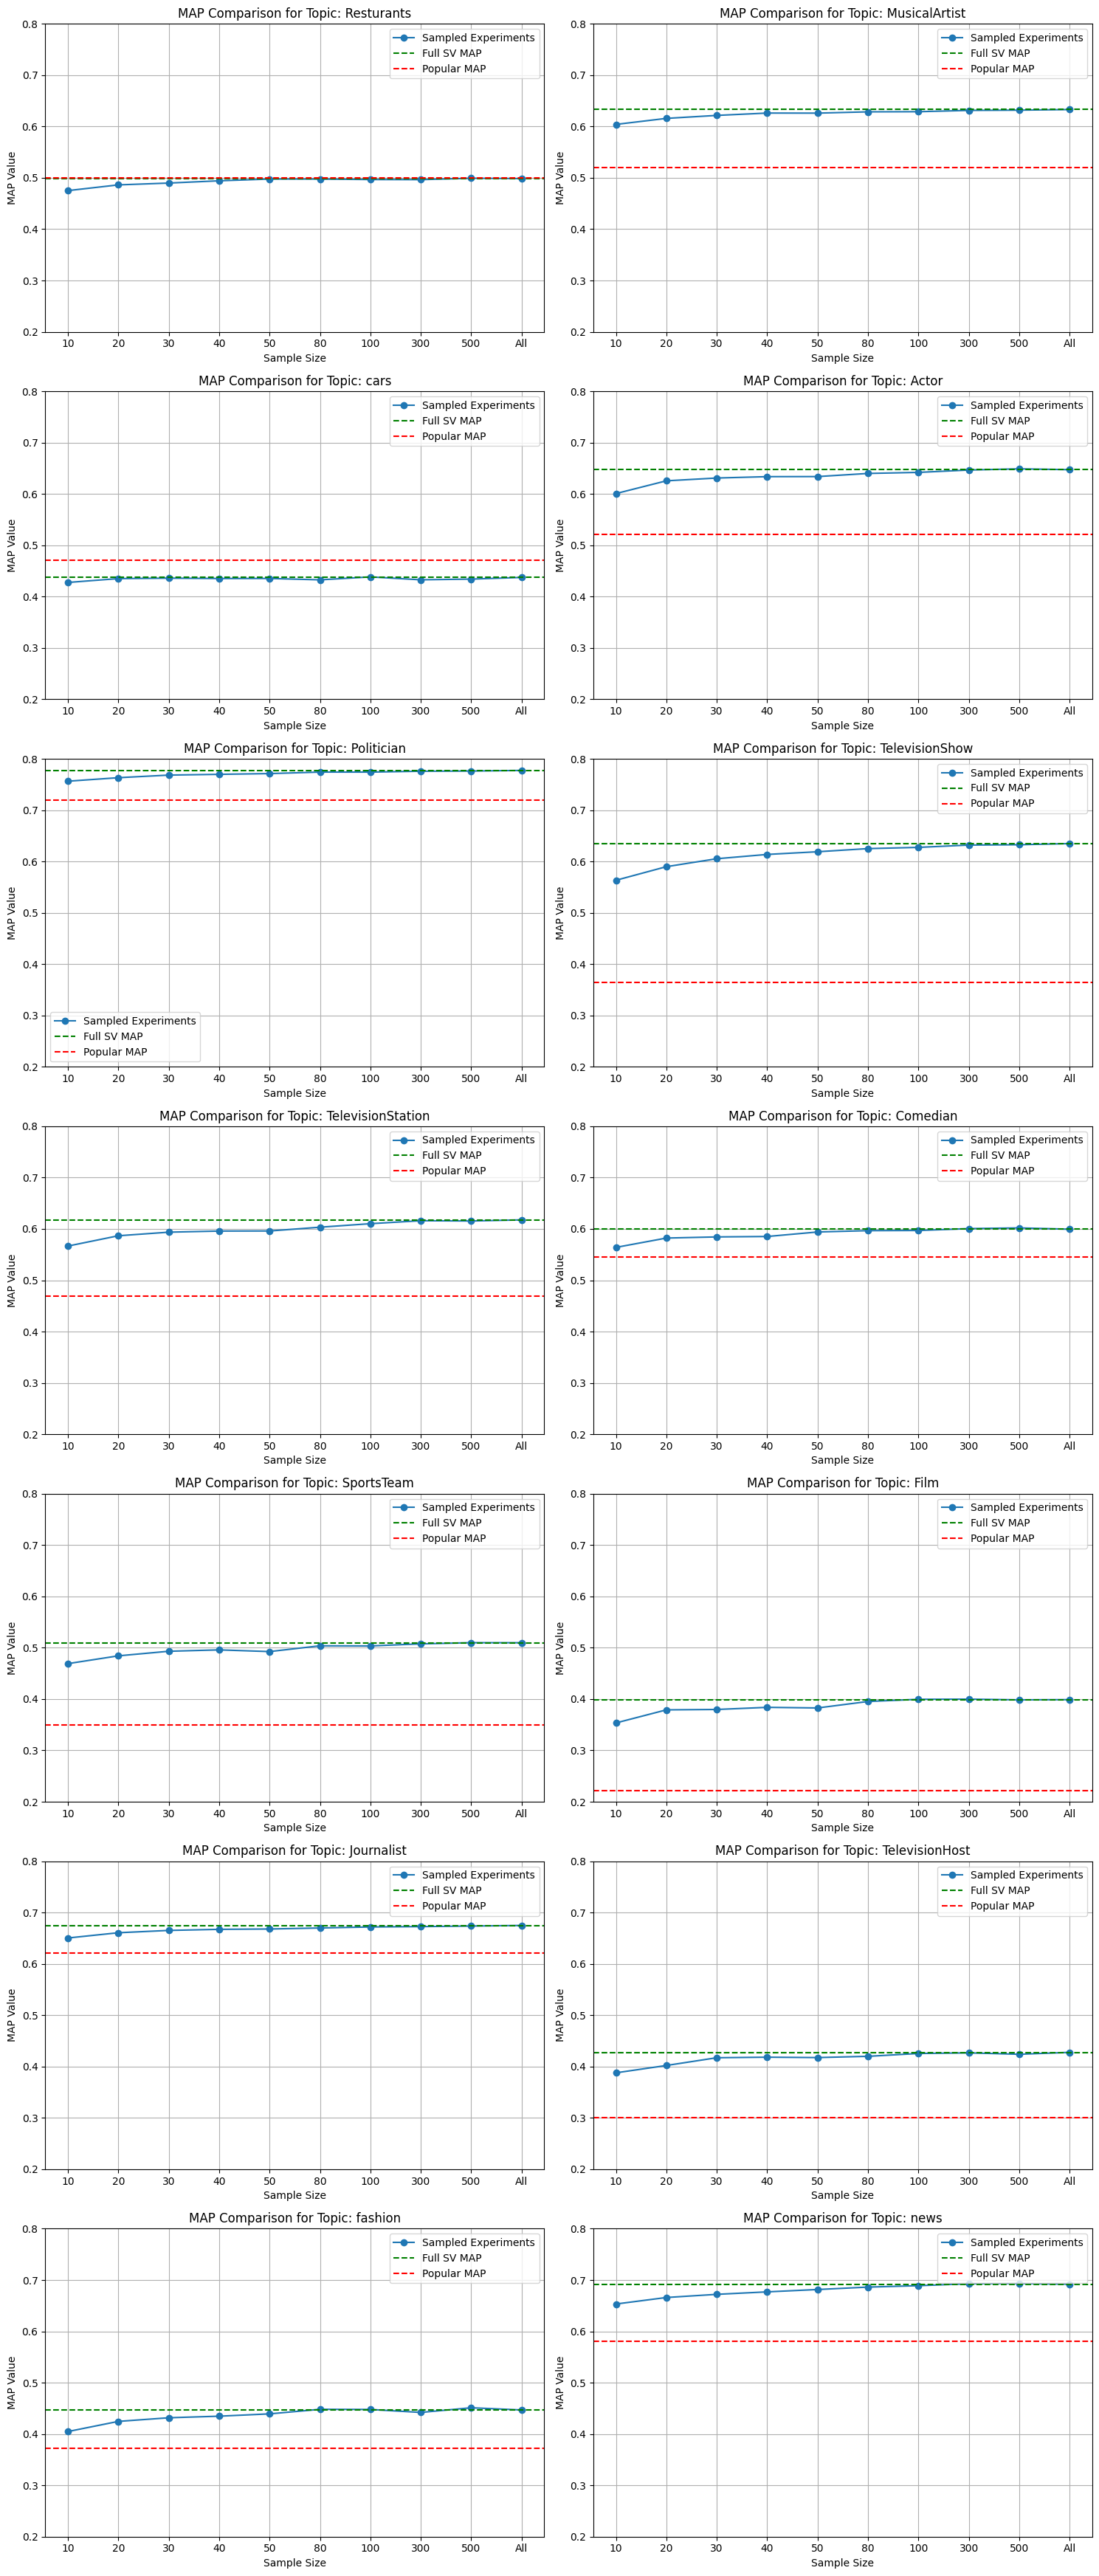

In [102]:
import matplotlib.pyplot as plt
import math


columns_to_show = [col for col in map_result.columns if 'map' in col]
threshold_restuls = map_all_topics[['topic']+columns_to_show].groupby(by='topic').mean().reset_index()


# 1. Determine layout size
num_topics = len(topic_list)
cols = 2  # You can change this to 3 if you want wider rows
rows = math.ceil(num_topics / cols)

# 2. Create the subplots
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()  # Flatten the 2D array of axes for easy iteration

for i, selected_topic in enumerate(topic_list):
    ax = axes[i]
    
    # Get the data for the current topic
    row = threshold_restuls[threshold_restuls["topic"] == selected_topic].iloc[0]
    
    # Data preparation
    x_labels = ['10', '20', '30', '40', '50', '80', '100', '300', '500', '5000']
    y_values = [row[f'exp_sv_sample__{value}_map'] for value in x_labels]
    x_labels[-1] = 'All'
    x_labels
    
    
    # 3. Plotting on the specific subplot (ax)
    ax.plot(x_labels, y_values, marker='o', label='Sampled Experiments')

    # Calculate Y limits based on your logic
    max_y = 0.8#= max(row['fullsv_map'], row['popular_map']) + 0.05
    min_y = 0.2#= min(row['fullsv_map'], row['popular_map']) - 0.05
    
    # Add horizontal lines
    ax.axhline(y=row['fullsv_map'], color='green', linestyle='--', label='Full SV MAP')
    ax.axhline(y=row['popular_map'], color='red', linestyle='--', label='Popular MAP')
    
    # Styling the subplot
    ax.set_title(f"MAP Comparison for Topic: {selected_topic}")
    ax.set_xlabel("Sample Size")
    ax.set_ylabel("MAP Value")
    ax.set_ylim(min_y, max_y)
    ax.legend(loc='best')
    ax.grid(True)

# 4. Hide any unused subplots (if topic count is odd)
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

# 5. Final layout adjustments and save
plt.tight_layout()
plt.savefig('all_topics_comparison2.png', dpi=300)
plt.show()

# TSNE reflection

# Generate data for Tensorboard Embeddings Projector

In [34]:
import csv
import os
import numpy as np

# Define output paths
output_dir = 'outputs'
if not os.path.exists(output_dir):
    os.makedirs(output_dir)

vectors_path = os.path.join(output_dir, 'vectors.tsv')
metadata_path = os.path.join(output_dir, 'metadata.tsv')

with open(vectors_path, 'w', newline='', encoding='utf-8') as vec_file, \
     open(metadata_path, 'w', newline='', encoding='utf-8') as meta_file:
    
    vec_writer = csv.writer(vec_file, delimiter='\t')
    meta_writer = csv.writer(meta_file, delimiter='\t')
    
    # Write metadata header
    meta_writer.writerow(['Topic', 'Twitter Screen Name', 'Twitter Name'])
    
    count = 0
    for topic in all_topics:
        df = all_topics[topic]
        
        # Check if required columns exist
        if 'account_sv' not in df.columns:
            print(f"Skipping topic {topic}: 'account_sv' column missing")
            continue
            
        for _, row in df.iterrows():
            embedding = row['account_sv']
            
            # Ensure embedding is a valid numpy array of length 100
            if isinstance(embedding, np.ndarray) and len(embedding) == 100:
                # Write embedding vector
                vec_writer.writerow(embedding)
                
                # Get metadata fields
                screen_name = row.get('twitter_screen_name', '')
                # Try to find name, default to empty string if not found
                name = row.get('twitter_name', row.get('name', ''))
                
                # Write metadata
                meta_writer.writerow([topic, screen_name, name])
                count += 1

print(f"Successfully generated TensorBoard files with {count} embeddings.")
print(f"Vectors file: {vectors_path}")
print(f"Metadata file: {metadata_path}")

Successfully generated TensorBoard files with 276 embeddings.
Vectors file: outputs/vectors.tsv
Metadata file: outputs/metadata.tsv


# Attributes of the users in the experiment

In [171]:
def count_matches(row_list, comparison_set):
    return len(set(row_list).intersection(comparison_set))

In [189]:
current_topic = 'fashion'

account_list_int = [int(x) for x in df_for_all_topic[current_topic].head(20)['user_id'].values]

In [190]:
accounts_set = set(account_list_int)

df_users_with_attributes['match_count'] = df_users_with_attributes['friends_ids'].apply(lambda x: count_matches(x, accounts_set))

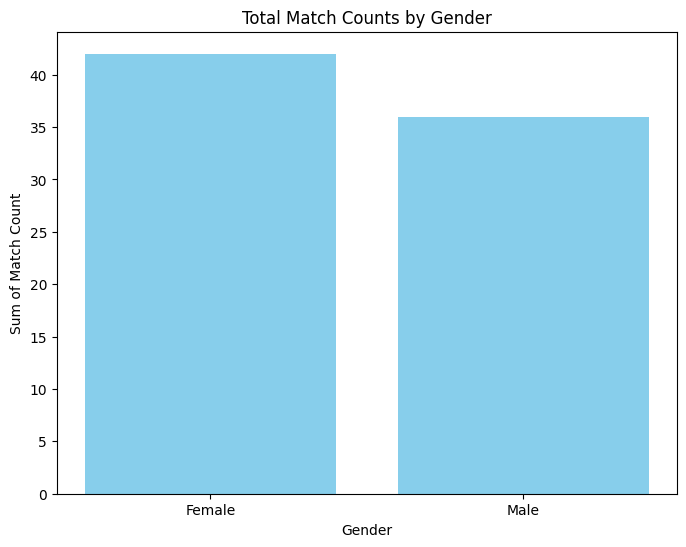

In [192]:
import pandas as pd
import matplotlib.pyplot as plt

# ... (Assuming df_users_with_attributes is already loaded) ...

# 1. Filter
clean_df = df_users_with_attributes.dropna(subset=['gender_prediction'])
clean_df = clean_df[clean_df['gender_label'] != 'Unknown']

# 2. Group
grouped_df = clean_df.groupby('gender_label')['match_count'].sum().reset_index()

# 3. Plot
plt.figure(figsize=(8, 6))

# We store the bar container to ensure x-axis alignment
bars = plt.bar(grouped_df['gender_label'], grouped_df['match_count'], color='skyblue')

# --- THE FIX ---
# Explicitly tell Matplotlib to use the gender names as labels for the x-axis positions
plt.xticks(
    ticks=range(len(grouped_df)),                # The positions (0, 1, 2...)
    labels=grouped_df['gender_label'],      # The names ('Male', 'Female'...)
    rotation=0                                   # Set to 45 if labels overlap
)
# ---------------

plt.xlabel('Gender')
plt.ylabel('Sum of Match Count')
plt.title('Total Match Counts by Gender')

plt.show()

# Classifier 2020c

In [35]:
sv_cls = SocialVec("2020c")

#init the classifier
sv_cls.init_classifier()

✅  Initializing Model
✅  Load Metadata


In [36]:
def check_classifier(single_user, expected_class, classifier_name):
    user = sv_cls.get_average_embeddings([sv_cls.get_userid(single_user)])[0]
    prediction = sv_cls.classifier.predict(classifier_name, user)
    if prediction[0] == expected_class:
        print(f"TEST PASSED. Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")
    else:
        print(f"FAILED! Expected: {expected_class}, Got: {prediction[0]}, confidence: {prediction[1]}")


In [37]:
check_classifier("BarackObama", "Democrat", "political")
check_classifier("ChickfilA", "Republican", "political")
check_classifier("RapSheet", "Male", "gender")
check_classifier("ChelseaHouska", "Female", "gender")
check_classifier("RASHEEDA", "AfrAmerican", "ethnicity")
check_classifier("Country_Words", "Caucasian", "ethnicity")
check_classifier("NASA", "Degree", "education")
check_classifier("illuminatihotts", "HighSchool", "education")
check_classifier("ToysRUs", "Yes", "children")
check_classifier("donaldglover", "No", "children")

TEST PASSED. Expected: Democrat, Got: Democrat, confidence: 0.9980640703579411
TEST PASSED. Expected: Republican, Got: Republican, confidence: 0.9834940433502197
TEST PASSED. Expected: Male, Got: Male, confidence: 0.9999228715896606
TEST PASSED. Expected: Female, Got: Female, confidence: 0.9999999816693634
TEST PASSED. Expected: AfrAmerican, Got: AfrAmerican, confidence: 0.9999979927467848
TEST PASSED. Expected: Caucasian, Got: Caucasian, confidence: 0.999997615814209
TEST PASSED. Expected: Degree, Got: Degree, confidence: 0.8461308479309082
TEST PASSED. Expected: HighSchool, Got: HighSchool, confidence: 0.16317451000213623
TEST PASSED. Expected: Yes, Got: Yes, confidence: 0.9179730415344238
TEST PASSED. Expected: No, Got: No, confidence: 0.994706769939512


In [279]:
classifier_name_list = ["political", "gender", "ethnicity", "education", "children"]
classifier_name_list = ["age"]

In [44]:
df_subset = df_users.copy()

In [280]:
for idx, user in tqdm(df_subset.iterrows(),total=df_subset.shape[0]):
    for classifier_name in classifier_name_list:
        emb, sv_len = sv_cls.get_average_embeddings(user['friends_ids'])
        cls = sv_cls.classifier.predict(classifier_name, emb)
        df_subset.at[idx, "SocialVec_len"] = sv_len
        df_subset.at[idx, classifier_name] = cls[0]
        df_subset.at[idx, f"{classifier_name}_proba"] = cls[1]


  0%|          | 0/11153 [00:00<?, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [46]:
df_subset[df_subset['topic']=='SportsTeam']['gender'].value_counts()

Male      545
Female    146
Name: gender, dtype: int64

### Create seperate line per account that we check

In [48]:
df_exploded = df_subset.explode('experiment_accounts')
df_exploded = df_exploded.reset_index(drop=True)

### Create dataframe with account_id to account_name mapping

In [49]:
experiment_accounts_df = pd.DataFrame({"account_id":df_exploded['experiment_accounts'].unique()})
experiment_accounts_df['account_id'] = experiment_accounts_df['account_id'].astype(int)
experiment_accounts_df['account_name'] = experiment_accounts_df['account_id'].apply(lambda x: sv_cls.get_screen_name(x))

In [50]:
df_exploded = pd.merge(df_exploded, experiment_accounts_df, left_on='experiment_accounts', right_on='account_id')

In [58]:
account_count_in_exploded = df_exploded.groupby(by=['account_name']).count()

In [ ]:
account_to_check = 'nautica'

df_exploded[df_exploded['account_name']==account_to_check].XXX.value_counts()

Male      64
Female    45
Name: gender, dtype: int64

## Find Accounts with Extreme Value Count Ratios

For each topic (political, gender, ethnicity, education, children), find 4 accounts where the distribution is most extreme (one category dominates)

In [63]:
def calculate_extreme_ratio(value_counts):
    """
    Calculate how extreme a distribution is by taking the ratio of the most common value
    to the sum of all other values. Higher ratio means more extreme.
    """
    if len(value_counts) < 2:
        return float('inf')  # If only one category, it's maximally extreme
    
    most_common = value_counts.iloc[0]
    rest_sum = value_counts.iloc[1:].sum()
    
    if rest_sum == 0:
        return float('inf')
    
    return most_common / rest_sum

# Topics to analyze
topics = ['political', 'gender', 'ethnicity', 'education', 'children']

# Store results
extreme_accounts_results = {}

for topic in topics:
    print(f"\n{'='*70}")
    print(f"Analyzing topic: {topic.upper()}")
    print(f"{'='*70}")
    
    unique_accounts = df_exploded['account_name'].unique()
    account_ratios = []
    
    for account in unique_accounts:
        account_data = df_exploded[df_exploded['account_name'] == account][topic].value_counts()
        
        # Only consider accounts with data for this topic
        if len(account_data) > 0:
            extreme_ratio = calculate_extreme_ratio(account_data)
            account_ratios.append({
                'account_name': account,
                'extreme_ratio': extreme_ratio,
                'value_counts': account_data,
                'total_count': account_data.sum(),
                'dominant_category': account_data.index[0] if len(account_data) > 0 else None,
                'dominant_percentage': (account_data.iloc[0] / account_data.sum() * 100) if len(account_data) > 0 else 0
            })
    
    # Group accounts by dominant category
    from collections import defaultdict
    category_groups = defaultdict(list)
    
    for account in account_ratios:
        category_groups[account['dominant_category']].append(account)
    
    # Sort each category group by extreme ratio and get top 5
    extreme_accounts_results[topic] = {}
    
    for category, accounts in category_groups.items():
        # Sort by extreme ratio (descending) and get top 5
        accounts_sorted = sorted(accounts, key=lambda x: x['extreme_ratio'], reverse=True)[:5]
        extreme_accounts_results[topic][category] = accounts_sorted
        
        # Display results
        print(f"\n{'-'*70}")
        print(f"Top 5 accounts with '{category}' as dominant category:\n")
        for i, result in enumerate(accounts_sorted, 1):
            print(f"{i}. {result['account_name']}")
            print(f"   Dominant Category: {result['dominant_category']} ({result['dominant_percentage']:.1f}%)")
            print(f"   Extreme Ratio: {result['extreme_ratio']:.2f}")
            print(f"   Total samples: {result['total_count']}")
            print(f"   Distribution:")
            for cat, count in result['value_counts'].items():
                percentage = (count / result['total_count'] * 100)
                print(f"      {cat}: {count} ({percentage:.1f}%)")
            print()


Analyzing topic: POLITICAL

----------------------------------------------------------------------
Top 5 accounts with 'Democrat' as dominant category:

1. HiddenFigures
   Dominant Category: Democrat (97.8%)
   Extreme Ratio: 44.00
   Total samples: 90
   Distribution:
      Democrat: 88 (97.8%)
      Republican: 2 (2.2%)

2. sense8
   Dominant Category: Democrat (95.4%)
   Extreme Ratio: 20.60
   Total samples: 108
   Distribution:
      Democrat: 103 (95.4%)
      Republican: 5 (4.6%)

3. lmillernpr
   Dominant Category: Democrat (94.6%)
   Extreme Ratio: 17.50
   Total samples: 74
   Distribution:
      Democrat: 70 (94.6%)
      Republican: 4 (5.4%)

4. GameGrumps
   Dominant Category: Democrat (94.2%)
   Extreme Ratio: 16.36
   Total samples: 243
   Distribution:
      Democrat: 229 (94.2%)
      Republican: 14 (5.8%)

5. NPRinskeep
   Dominant Category: Democrat (94.1%)
   Extreme Ratio: 15.98
   Total samples: 815
   Distribution:
      Democrat: 767 (94.1%)
      Republican: 

## Radar Charts: Account Demographics vs Population Baseline

Create spider/radar graphs showing the demographic profile of extreme accounts compared to the overall population

# Modified calculation of ratio

In [471]:
sampled_accounts = ['ChickfilA', 'NineWest', 'DeerGear', 
                    'ArianaGrande', 'celtics', 'SnoopDogg',
                    'Bugatti','TheDailyShow', 'SarahKSilverman',]

## Updated spider graph

In [73]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from math import pi
import math

def create_demographic_radar_grid(df, account_pairs, charts_per_row=2, account_col='account_selected_for'):
    """
    Generates a grid of radar charts comparing pairs of accounts.
    
    Parameters:
    - df: The pandas DataFrame containing the data.
    - account_pairs: A list of tuples, e.g., [('McDonalds', 'ChickfilA'), ('McDonalds', 'BurgerKing')]
    - charts_per_row: Integer, number of charts to display in a single row.
    - account_col: The column name for the account identifier.
    """
    
    # 1. Define metrics and targets
    metrics = {
        'political': 'Democrat',
        'gender': 'Female',
        'ethnicity': 'Caucasian', 
        'education': 'Degree',
        'children': 'Yes'
    }
    
    # Helper to calculate ratios
    def get_ratios(account_name):
        subset = df[df[account_col] == account_name]
        if subset.empty:
            return [0] * len(metrics)
        
        ratios = []
        for col, target in metrics.items():
            # Handle potential missing columns gracefully
            if col not in subset.columns:
                ratios.append(0)
                continue
            
            # clean whitespace just in case
            try:
                col_data = subset[col].astype(str).str.strip()
                count = (col_data == target).sum()
                total = len(subset)
                ratios.append(count / total if total > 0 else 0)
            except Exception:
                ratios.append(0)
        return ratios

    # 2. Setup Grid
    num_plots = len(account_pairs)
    num_rows = math.ceil(num_plots / charts_per_row)
    
    # Calculate angles
    N = len(metrics)
    angles = [n / float(N) * 2 * pi for n in range(N)]
    angles += angles[:1]
    
    # Labels for the axes
    labels = [f"{k.capitalize()}\n({v})" for k, v in metrics.items()]
    
    # Create Figure
    fig = plt.figure(figsize=(6 * charts_per_row, 6 * num_rows))
    
    for idx, (acc1, acc2) in enumerate(account_pairs):
        # Add subplot with polar projection
        ax = fig.add_subplot(num_rows, charts_per_row, idx + 1, polar=True)
        
        # Get data
        values1 = get_ratios(acc1)
        values2 = get_ratios(acc2)
        
        # Close the loop
        values1 += values1[:1]
        values2 += values2[:1]
        
        # Plot acc1
        ax.plot(angles, values1, 'o', linewidth=2, linestyle='-', label=acc1, color='#1f77b4')
        ax.fill(angles, values1, alpha=0.15, color='#1f77b4')
        
        # Plot acc2
        ax.plot(angles, values2, 'o', linewidth=2, linestyle='--', label=acc2, color='#d62728')
        ax.fill(angles, values2, alpha=0.1, color='#d62728')
        
        # Formatting
        plt.xticks(angles[:-1], labels, color='grey', size=8)
        ax.set_rlabel_position(0)
        plt.yticks([0.2, 0.4, 0.6, 0.8], ["20%", "40%", "60%", "80%"], color="grey", size=7)
        plt.ylim(0, 1)
        
        plt.title(f"{acc1} vs {acc2}", size=11, y=1.1)
        plt.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize='small')

    plt.tight_layout()
    plt.savefig('radar_grid.png', bbox_inches='tight')


In [278]:
df_exploded

,tweet_id,user_id,location,screen_name,description,verified,followers_count,friends_count,listed_count,favourites_count,...,gender,gender_proba,ethnicity,ethnicity_proba,education,education_proba,children,children_proba,account_id,account_name
0,1575468557818888196,928119115117727744,"Michigan, USA",sjlibbmc,It is what it is and I yam what I yam.,False,704.0,3775.0,2.0,11388.0,...,Male,0.400435,Caucasian,0.957124,Degree,0.272739,No,0.582786,15485441,jimmyfallon
1,1554114931599020033,349902568,"Florida, USA",onevegetabletwo,shut up • she/they • 🔜 Imagine 🔜 Summoning Fes...,False,495.0,1460.0,0.0,9972.0,...,Female,0.792882,Caucasian,0.811331,Degree,0.659900,No,0.796340,15485441,jimmyfallon
2,1574828399725408256,767381690964586496,"California, USA",DrKory911,#PsychologyOfDREAM #ArtificialIntelligence 🕯 #...,False,328.0,4346,8,9963,...,Female,0.948100,Caucasian,0.983989,Degree,0.494603,No,0.858027,15485441,jimmyfallon
3,1550169283774365696,23112843,Georgia,IamGman2112,Reverse Psychologist,False,33.0,2002.0,2.0,278.0,...,Male,0.853311,Caucasian,0.964558,HighSchool,0.221150,No,0.475677,15485441,jimmyfallon
4,1547534529665146882,43529827,"New Jersey, USA",BrandieW818,NaN,False,56.0,786.0,2.0,3962.0,...,Female,0.003835,Caucasian,0.852555,HighSchool,0.423723,No,0.012336,15485441,jimmyfallon
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
449782,1561351745267109888,69864675,United States,PurlingPony,"love animals🐶🐱🐴🦙🦉🐝🦒, knitting, history, geneal...",False,146.0,1019,2,121102,...,Female,0.179717,Caucasian,0.964386,HighSchool,0.801991,Yes,0.073313,16331217,HistoryCenter
449783,1552263523073462274,118424145,"Washington, DC",historybyte,Historian. Writer. Professor. Author of Lipsti...,False,1692.0,2650.0,76.0,14250.0,...,Female,0.481165,Caucasian,0.857407,HighSchool,0.861434,No,0.223842,16331217,HistoryCenter
449784,1551037345855688706,4510200382,"Ohio, USA",Temujin52,"Army Veteran, Patriot, Republican, Conservativ...",False,2626.0,3317.0,4.0,102968.0,...,Male,0.354774,Caucasian,0.949180,HighSchool,0.283964,No,0.333191,16331217,HistoryCenter
449785,1558825784348901380,49084485,"Pennsylvania, USA",mjminpgh,looking for truth beauty and compassion in thi...,False,426.0,3034,8,33307,...,Male,0.250012,Caucasian,0.933107,HighSchool,0.711941,No,0.284068,16331217,HistoryCenter


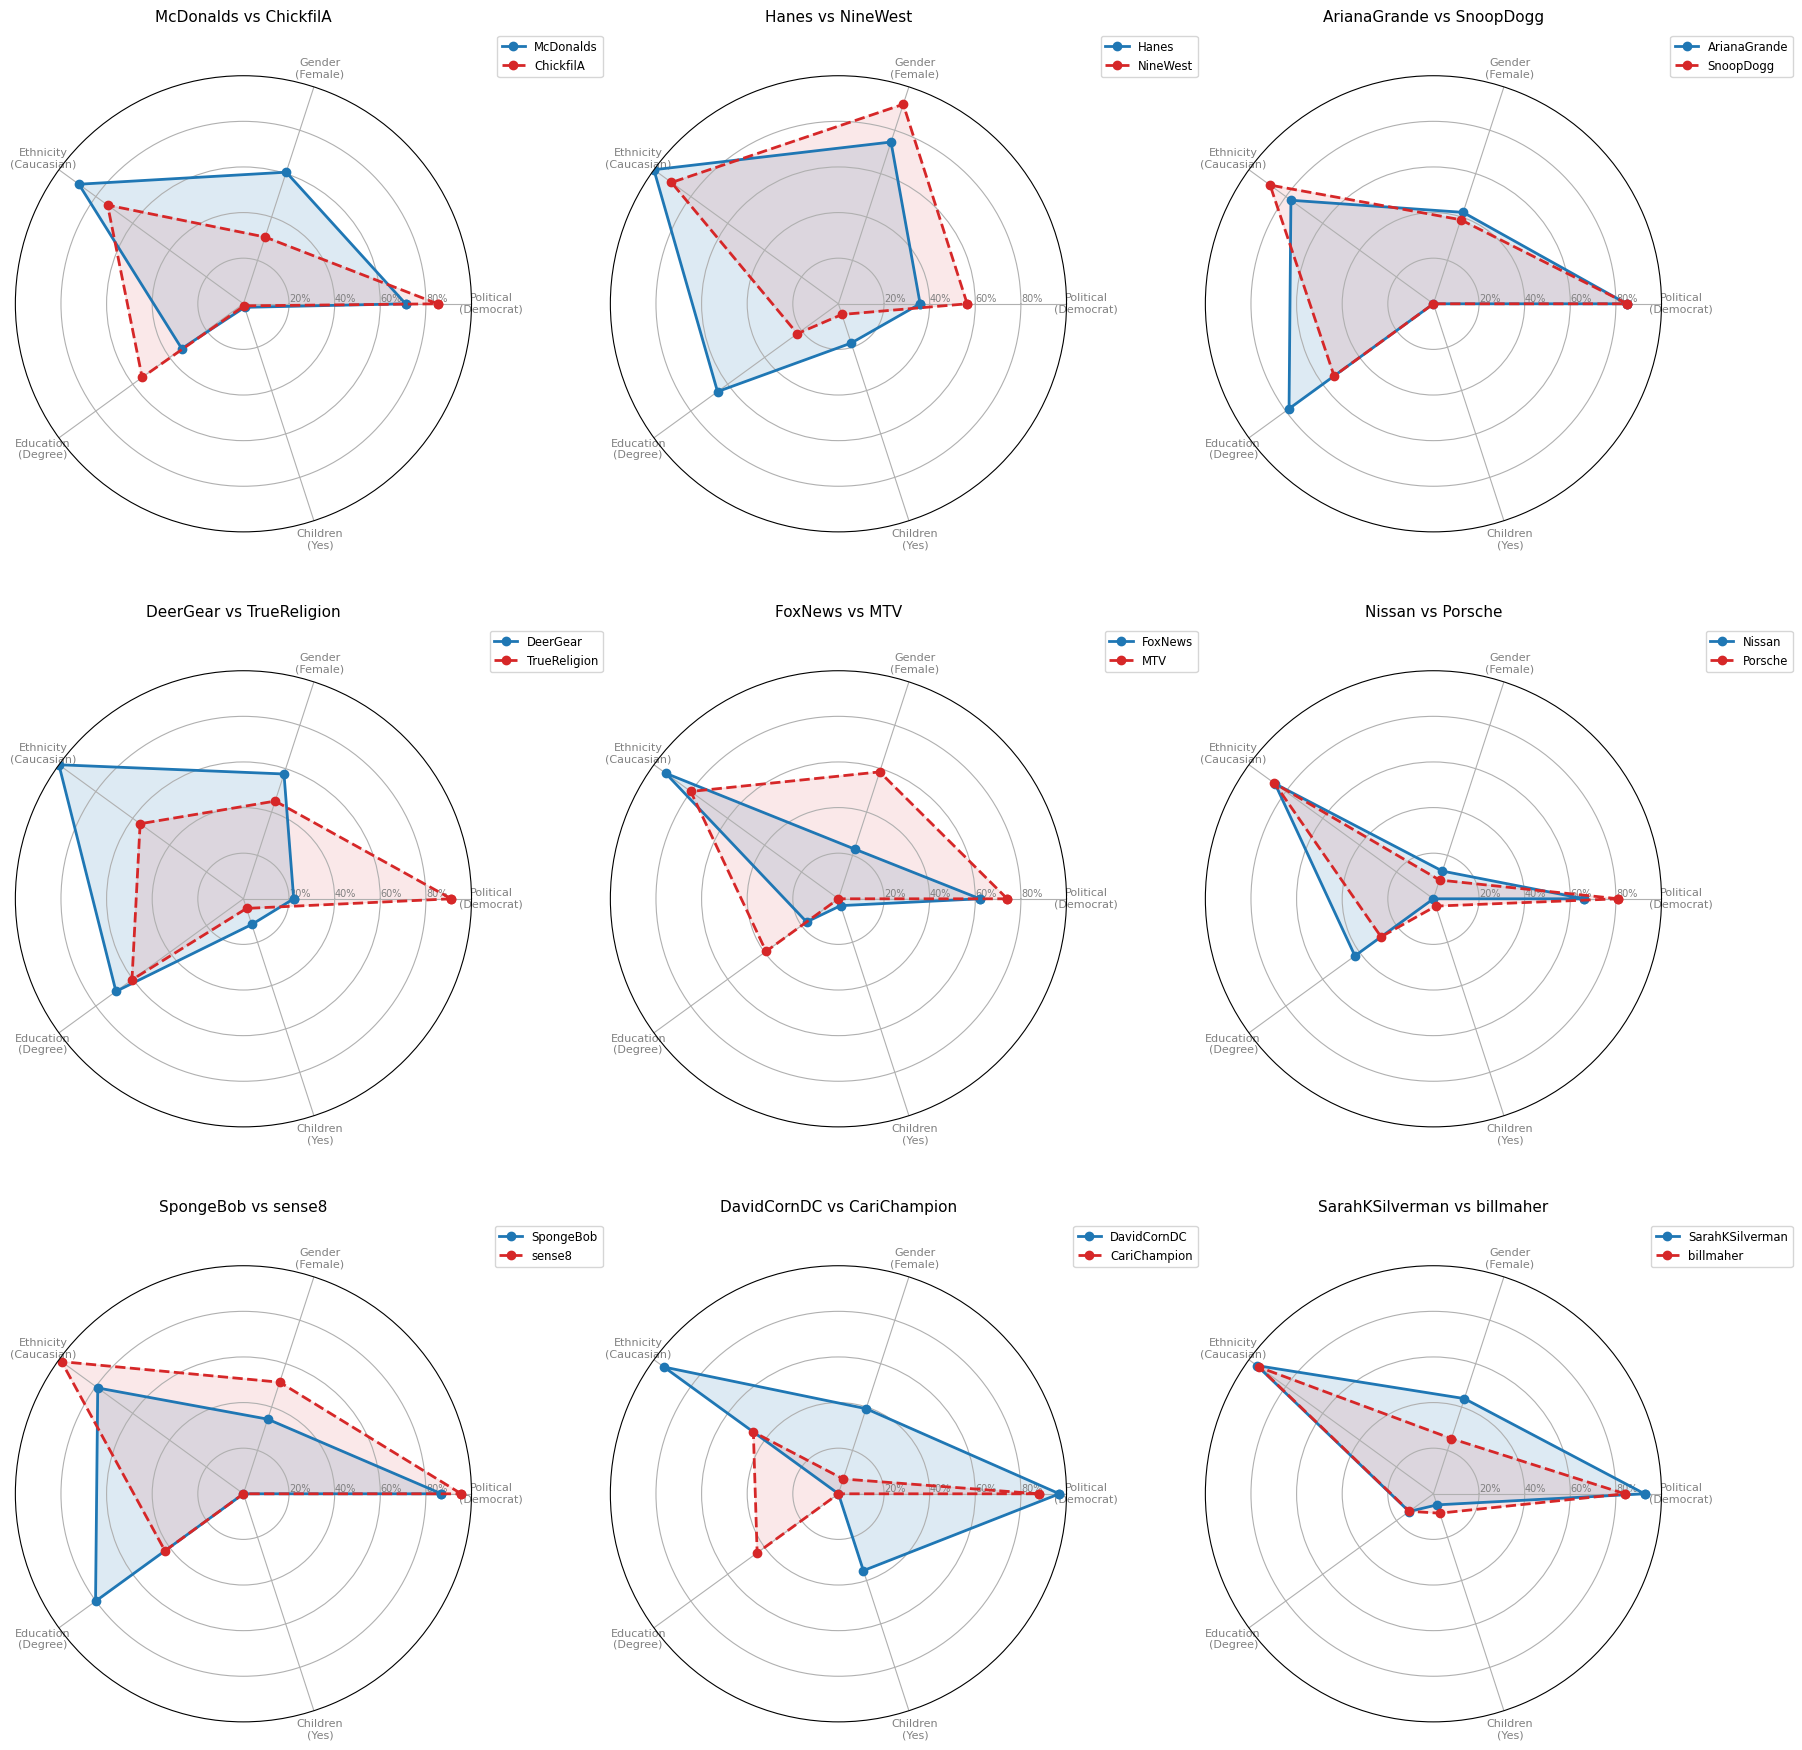

In [76]:

# Define pairs to compare
pairs_to_plot = [
    ('McDonalds', 'ChickfilA'),
    ('Hanes', 'NineWest'),
    ('ArianaGrande', 'SnoopDogg'),
    ('DeerGear', 'TrueReligion'),
    ('FoxNews','MTV'),
    ('Nissan','Porsche'),
    ('SpongeBob','sense8'),
    ('DavidCornDC','CariChampion'),
    ('SarahKSilverman','billmaher')
]

# Run function
create_demographic_radar_grid(df_exploded, pairs_to_plot, charts_per_row=3)

# Rate the accounts by LLM

For each account we use the same sample of 50 accounts for which we will get the names and provide them to the LLM (to be as fair as the SocialVec)

In [68]:
def get_name(x):
    try:
        return sv_cls.entities[sv_cls.entities['twitter_id']==x]['name'].iloc[0]
    except:
        return

### For each user in the df_for_all_topic:
* sample the same 50 accounts as for SocialVec and create a string with the name of accounts the user follows.
* The names are of the accounts that exist in SV (which are the popular account of the sample of 50)

In [70]:
accounts_for_llm = pd.DataFrame()

#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(topic_list)):
    df_for_topic = df_for_all_topic[topic]

    for i, user in tqdm(df_for_topic.iterrows()):    

        pbar.set_description(f"Processing topic: {topic} user: {user['screen_name']}")
        user_all_accounts = list_str(user['friends_ids'])
        
        # All accounts that the user follows except the ones from the topic...
        user_all_accounts_except_selected_accounts = list( set(user_all_accounts) - set(user['topic_accounts_str']) )
                
        sample_size = 50 

        if sample_size < len(user_all_accounts_except_selected_accounts):
            random.seed(76)
            acounts_for_sample = random.sample(user_all_accounts_except_selected_accounts,sample_size)
        else:
            acounts_for_sample = user_all_accounts_except_selected_accounts

        account_names = [get_name(x) for x in acounts_for_sample ]
        account_string = ", ".join([x for x in account_names if x])
        df_for_all_topic[topic].at[i,'account_names'] = account_string


  0%|          | 0/14 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

... (5 outputs left out)

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

In [ ]:
לעשות ספירה של כל חשבון כמה בדגימה עוקבים אחריו
לקחת זוגות חשבונות שהרבה עוקבים אחריו
ולהציג לא מול הפופלרי אלא שתי ישויות מול השני



In [ ]:
import dspy

# For Azure OpenAI, we set these environment variables
api_key = "ccc6a375567a437da95b127a45c4e7ab"
endpoint_url = "https://infradevtest.openai.azure.com/"
openai_api_version="2025-01-01-preview"

lm = dspy.LM(
#    'azure/gpt-4o',
    api_key= api_key,
    api_base= endpoint_url,
    api_version= openai_api_version,
    model='azure/gpt-4o'
)
dspy.configure(lm=lm)
dspy.settings.configure(lm=lm)

class TwitterRecommendation(dspy.Signature):
    """
    given the below Twitter user, to which we provide a sampled list of accounts the user already follows, and a list of possible accounts to recommend for the user to follow, create a prioritized recommendation list.
    You must rank the entire list provided to you. 
    Try to deduce what you think the user might like based on the list of accounts they already follow.
    Return ONLY a valid list object with the ranked account twitter_user_id sorted by relevance (highest to lowest). Do not include name or reasoning.
    Example format: [71026122, 141341662, 567562934, ...]
    """
    
    followed_accounts = dspy.InputField(desc="Sampled list of other accounts the user already follows")
    potential_accounts = dspy.InputField(desc="JSON list of potential accounts to recommend with twitter_user_id and names")
    ranked_ids = dspy.OutputField(desc="list with the account twitter_user_id sorted by priority as a ranked key")

class Recommender(dspy.Module):
    def __init__(self):
        super().__init__()
        self.generate_ranking = dspy.Predict(TwitterRecommendation)
    
    def forward(self, followed_accounts, potential_accounts):
        return self.generate_ranking(
            followed_accounts=followed_accounts,
            potential_accounts=potential_accounts
    )

recommender = Recommender()

In [ ]:
curr_user['account_names']

In [135]:
#for topic in (pbar := tqdm(list(set(topic_list) - set(['Resturants','MusicalArtist','cars'])))):
#for topic in (pbar := tqdm(topic_list)):
for topic in (pbar := tqdm(missing_topic_list)):
    df_for_topic = df_for_all_topic[topic]
              
    for i, curr_user in tqdm(df_for_topic.iterrows()):  

        pbar.set_description(f"Processing topic: {topic} user: {curr_user['screen_name']}")

        ### Get a JSON with the sorted potential accounts
        df_for_ranking = all_topics[curr_user['topic']].sort_values(by='followers_count', ascending=False).reset_index(drop=True)
        df_for_ranking.index = df_for_ranking.index + 1
        df_for_ranking = df_for_ranking.reset_index()
        accounts_to_be_rated = df_for_ranking[['twitter_user_id','twitter_name']].to_json(orient='records')

        ### Sample of other, non related accounts that the user follows:
        sample_accounts = curr_user['account_names']

        try:
            res = recommender(followed_accounts = sample_accounts, potential_accounts = accounts_to_be_rated)              
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = res['ranked_ids']
        except:
            df_for_all_topic[topic].at[i,'llm_ranked_list'] = '[]'
    
    
            

  0%|          | 0/10 [00:00<?, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

0it [00:00, ?it/s]

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



In [139]:
with open('df_for_all_topic_with_llm.pkl', 'wb') as outp:
    pickle.dump(df_for_all_topic, outp, pickle.HIGHEST_PROTOCOL)

# Calculate LLM MRR

In [220]:
import ast

def calculate_llm_map(row):
    """
    Calculate MAP for LLM recommendations.
    Returns a tuple of (positions_list, map_score)
    """
    # Parse the llm_ranked_list if it's a string
    if isinstance(row['llm_ranked_list'], str):
        try:
            llm_ranked_list = ast.literal_eval(row['llm_ranked_list'])
        except:
            return ([], 0.0)
    else:
        llm_ranked_list = row['llm_ranked_list']
    
    # Handle empty or invalid lists
    if not isinstance(llm_ranked_list, list) or len(llm_ranked_list) == 0:
        return ([], 0.0)
    
    # Get the topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in llm_ranked_list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            position = llm_ranked_list.index(int(account_id)) + 1
            positions.append(position)
        except ValueError:
            # Account not found in ranked list - skip it
            continue
    
    # Calculate MAP if we have positions
    if len(positions) > 0:
        # Sort positions to get them in order
        positions_sorted = sorted(positions)
        
        # MAP calculation: sum(i/position_i) / len(positions)
        # where i is the ideal rank (1, 2, 3...) and position_i is actual rank
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

In [204]:
for i, item in enumerate(eval(row_sample['llm_ranked_list'])):
    if item in row_sample['topic_accounts']:
        suffix = "<-----"
    else:
        suffix = ""
    
    print(f"{i+1}. {item}{suffix}")
    

1. 54502344<-----
2. 27650674<-----
3. 323319539<-----
4. 1545994664<-----
5. 57016932<-----
6. 2650413864
7. 494939290<-----
8. 349714440
9. 98955572
10. 15676492
11. 66395780
12. 14219877
13. 43430484
14. 16529238
15. 258730549
16. 17341358
17. 23689478
18. 249090055
19. 260414018


In [221]:
for i, row in tqdm(df_for_all_topic[topic].iterrows()):
    calculate_llm_map(row)

0it [00:00, ?it/s]

In [217]:
if not row['llm_ranked_list']:
    print("nan")

In [222]:

# Apply the calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['llm_ranked_positions', 'llm_MAP']] = df_for_all_topic[topic].apply(
        calculate_llm_map, axis=1, result_type='expand'
    )

print("LLM MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist
Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow
Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news
LLM MAP calculation complete!


In [226]:
for topic in tqdm(topic_list):
    print(f"{topic}: {df_for_all_topic[topic]['llm_MAP'].mean()}")

  0%|          | 0/14 [00:00<?, ?it/s]

Resturants: 0.49611600329349964
MusicalArtist: 0.6672657842127933
cars: 0.4093615918473357
Actor: 0.6617178981090548
Politician: 0.8106131994039946
TelevisionShow: 0.6366395396227693
TelevisionStation: 0.6637465750313696
Comedian: 0.6551057736128274
SportsTeam: 0.5709084670173513
Film: 0.39911784575270215
Journalist: 0.7044808492361937
TelevisionHost: 0.5218947251522119
fashion: 0.49269525613737547
news: 0.7162031290550489


# Calculate SocialVec MAP (Fair Comparison with LLM)
Implement SocialVec MAP calculation using the same methodology as LLM for direct comparison.

In [227]:
def calculate_sv_map(row):
    """
    Calculate MAP for SocialVec recommendations using identical methodology to LLM.
    Returns a tuple of (positions_list, map_score)
    """
    # Get the same sample of accounts used for LLM (50 accounts)
    user_all_accounts = list_str(row['friends_ids'])
    user_all_accounts_except_selected_accounts = list(set(user_all_accounts) - set(row['topic_accounts_str']))
    
    sample_size = 50
    if sample_size < len(user_all_accounts_except_selected_accounts):
        random.seed(76)  # Same seed as used for LLM
        accounts_for_sample = random.sample(user_all_accounts_except_selected_accounts, sample_size)
    else:
        accounts_for_sample = user_all_accounts_except_selected_accounts
    
    # Get user vector from sampled accounts
    user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]
    
    # Get the topic's accounts dataframe
    topic = row['topic']
    topic_df = all_topics[topic]
    
    # Rank all accounts using SocialVec
    sv_ranked = get_sv_rank(user_vec, topic_df)
    
    # Get topic accounts for this user
    topic_accounts = row['topic_accounts']
    
    # Find positions of topic_accounts in sv_ranked list
    positions = []
    for account_id in topic_accounts:
        try:
            # Find the position (1-indexed) of this account in the ranked list
            account_row = sv_ranked[sv_ranked['twitter_user_id'] == account_id]
            if not account_row.empty:
                position = int(account_row['rank'].iloc[0])
                positions.append(position)
        except:
            continue
    
    # Calculate MAP if we have positions (same formula as LLM)
    if len(positions) > 0:
        positions_sorted = sorted(positions)
        map_score = sum((i+1)/pos for i, pos in enumerate(positions_sorted)) / len(positions_sorted)
    else:
        map_score = 0.0
    
    return (positions, map_score)

In [267]:
row_sample = df_for_all_topic[topic].iloc[100]

In [ ]:
for i, item in enumerate(eval(row_sample['llm_ranked_list'])):
    if item in row_sample['topic_accounts']:
        suffix = "<-----"
    else:
        suffix = ""
    
    print(f"{i+1}. {item}{suffix}")
    

In [269]:
accounts_for_sample = random.sample(row_sample['non_topic_accounts'], min(len(row_sample['non_topic_accounts']),50))

In [271]:
# Get user vector from sampled accounts
user_vec = sv.get_average_embeddings(list_str(accounts_for_sample))[0]

# Get the topic's accounts dataframe
topic = row_sample['topic']
topic_df = all_topics[topic]

selected_row_sv_rank = get_sv_rank(user_vec, all_topics[topic])
string_for_sv = "["+", ".join([str(val) for val in selected_row_sv_rank['twitter_user_id'].values])+"]"

In [272]:
for i, item in enumerate(eval(string_for_sv)):
    if item in row_sample['topic_accounts']:
        suffix = "<-----"
    else:
        suffix = ""
    
    print(f"{i+1}. {item}{suffix}")
    

1. 14075928
2. 2836421<-----
3. 742143<-----
4. 2467791
5. 1652541
6. 428333<-----
7. 14173315<-----
8. 807095<-----
9. 51241574<-----
10. 28785486<-----
11. 14511951<-----
12. 91180720<-----
13. 17469289
14. 15754281
15. 5988062
16. 26257166
17. 87818409<-----
18. 1367531
19. 890891
20. 1209936918


In [276]:
(1/2 + 2/3 + 3/6 + 4/7+ 5/8 + 6/9 + 7/10 + 8/11+9/12 +10/17)/10

0.6295269926152278

In [277]:
row_sample

tweet_id                                                                1558218515315924996
user_id                                                                           271177983
location                                                                           New York
screen_name                                                                 TalkingAbout_TV
description                               Talking About is a TV show and podcast focusin...
verified                                                                              False
followers_count                                                                      1757.0
friends_count                                                                          4150
listed_count                                                                             27
favourites_count                                                                      14256
statuses_count                                                                  

In [228]:
# Apply the SocialVec MAP calculation to all topics
for topic in tqdm(topic_list):
    print(f"Processing topic: {topic}")
    df_for_all_topic[topic][['sv_ranked_positions', 'sv_MAP']] = df_for_all_topic[topic].apply(
        calculate_sv_map, axis=1, result_type='expand'
    )

print("SocialVec MAP calculation complete!")

  0%|          | 0/14 [00:00<?, ?it/s]

Processing topic: Resturants
Processing topic: MusicalArtist


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: cars
Processing topic: Actor
Processing topic: Politician
Processing topic: TelevisionShow


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


Processing topic: TelevisionStation
Processing topic: Comedian
Processing topic: SportsTeam
Processing topic: Film
Processing topic: Journalist
Processing topic: TelevisionHost
Processing topic: fashion
Processing topic: news


/usr/local/lib/python3.10/dist-packages/scipy/spatial/distance.py:622: RuntimeWarning: invalid value encountered in scalar divide
  dist = 1.0 - uv / np.sqrt(uu * vv)


SocialVec MAP calculation complete!


In [229]:
# Compare SocialVec vs LLM MAP scores by topic
print("\nMAP Comparison: SocialVec vs LLM\n" + "="*50)
for topic in topic_list:
    sv_map_mean = df_for_all_topic[topic]['sv_MAP'].mean()
    llm_map_mean = df_for_all_topic[topic]['llm_MAP'].mean()
    print(f"{topic:20s} | SV: {sv_map_mean:.4f} | LLM: {llm_map_mean:.4f} | Diff: {sv_map_mean - llm_map_mean:+.4f}")


MAP Comparison: SocialVec vs LLM
Resturants           | SV: 0.4914 | LLM: 0.4961 | Diff: -0.0047
MusicalArtist        | SV: 0.6287 | LLM: 0.6673 | Diff: -0.0385
cars                 | SV: 0.4382 | LLM: 0.4094 | Diff: +0.0289
Actor                | SV: 0.6393 | LLM: 0.6617 | Diff: -0.0224
Politician           | SV: 0.7730 | LLM: 0.8106 | Diff: -0.0376
TelevisionShow       | SV: 0.6114 | LLM: 0.6366 | Diff: -0.0253
TelevisionStation    | SV: 0.6050 | LLM: 0.6637 | Diff: -0.0587
Comedian             | SV: 0.5899 | LLM: 0.6551 | Diff: -0.0652
SportsTeam           | SV: 0.4979 | LLM: 0.5709 | Diff: -0.0730
Film                 | SV: 0.3769 | LLM: 0.3991 | Diff: -0.0222
Journalist           | SV: 0.6693 | LLM: 0.7045 | Diff: -0.0351
TelevisionHost       | SV: 0.4255 | LLM: 0.5219 | Diff: -0.0964
fashion              | SV: 0.4423 | LLM: 0.4927 | Diff: -0.0504
news                 | SV: 0.6827 | LLM: 0.7162 | Diff: -0.0335
